# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

**Name:** Fida Nafeesa  
**Roll No:** IMS25079  
**Date:** November 2026

This notebook implements **recursive spectral modularity bisection** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, visualises every split, tracks four node-level metrics (degree, betweenness, closeness centrality and clustering) after each split, and discusses the results.

**Method reference:** M. E. J. Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582. The modularity matrix $B = A - \frac{kk^\top}{2m}$, the modularity score $Q=\frac{1}{4m}s^\top B s$ and the leading-eigenvector bipartition follow this paper.

**Notes on conventions**
* NetworkX numbers the 34 members `0…33` (the original paper uses `1…34`). `0` is the instructor *Mr. Hi* and `33` is the club administrator/president.
* Iteration `0` = whole graph as one community. Each successful bisection creates a new iteration.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
m_total = None  # set after the graph is loaded
TOL = 1e-10   # numerical tolerance for "eigenvalue <= 0" and sign thresholding

## 1. Data and the modularity matrix

In [2]:
G = nx.karate_club_graph()
nodes = list(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()
m_total = m
print(f"n = {n} nodes, m = {m} edges")

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)          # adjacency matrix
k = A.sum(axis=1)                                 # degree vector
B = A - np.outer(k, k) / (2 * m)                  # modularity matrix

# Sanity checks from the handout's proofs
print("A symmetric:            ", np.allclose(A, A.T))
print("B symmetric (Prop. 1):  ", np.allclose(B, B.T))
print("B @ 1 = 0 (Prop. 2):    ", np.allclose(B @ np.ones(n), 0))
print("sum(k) = 2m:            ", k.sum() == 2 * m)

# Ground truth split recorded by Zachary
truth = np.array([1 if G.nodes[i]["club"] == "Mr. Hi" else -1 for i in nodes])
print("Ground truth: Mr. Hi =", int((truth == 1).sum()), "members, Officer =", int((truth == -1).sum()), "members")

n = 34 nodes, m = 78 edges
A symmetric:             True
B symmetric (Prop. 1):   True
B @ 1 = 0 (Prop. 2):     True
sum(k) = 2m:             True
Ground truth: Mr. Hi = 17 members, Officer = 17 members


## 2. Modularity score and the spectral bipartition

For a labelling $s\in\{-1,+1\}^n$: $Q=\frac{1}{4m}s^\top B s$.  
For a general multi-community partition we use the equivalent form $Q=\frac{1}{2m}\sum_{i,j\ \text{same community}} B_{ij}$ (this equals the two-group formula when there are two groups, because $\sum_{ij}B_{ij}=0$). We verify our implementation against `networkx.community.modularity`.

In [3]:
def modularity_Q(B, communities, m):
    # Q = (1/2m) * sum over pairs in the same community of B_ij
    total = 0.0
    for c in communities:
        idx = np.array(sorted(c))
        total += B[np.ix_(idx, idx)].sum()
    return total / (2 * m)

def leading_eigenpair(M):
    # M is real symmetric (Prop. 1 / Thm. 1) -> use eigh (ascending eigenvalues)
    w, V = np.linalg.eigh(M)
    return w[-1], V[:, -1]

def bisect(B, C, generalized=False):
    # Try to split community C (list of node ids) using the restricted matrix B^(C).
    # Returns (lambda1, C_plus, C_minus); the parts are None if C is indivisible.
    C = sorted(C)
    BC = B[np.ix_(C, C)]                       # restricted modularity matrix B^(C)
    if generalized:                            # Newman (2006) eq. (6): subtract row sums on the diagonal
        BC = BC - np.diag(BC.sum(axis=1))
    lam, u = leading_eigenpair(BC)
    if lam <= TOL:                             # Theorem 3 stopping rule
        return lam, None, None
    s = np.where(u > TOL, 1, -1)               # s_i = +1 if (u1)_i > 0 else -1
    if generalized and (s @ BC @ s) / (4 * m_total) <= TOL:   # Newman: also require the *rounded* split to have dQ > 0
        return lam, None, None
    C_plus  = [C[i] for i in range(len(C)) if s[i] == 1]
    C_minus = [C[i] for i in range(len(C)) if s[i] == -1]
    if len(C_plus) == 0 or len(C_minus) == 0:  # degenerate: sign vector is constant
        return lam, None, None
    return lam, C_plus, C_minus

# Check: first bisection of the whole graph
lam, Cp, Cm = bisect(B, nodes)
s = np.array([1 if i in Cp else -1 for i in nodes])
print(f"lambda_1 = {lam:.4f}")
print(f"Q via s^T B s / 4m          = {s @ B @ s / (4*m):.6f}")
print(f"Q via community-sum formula = {modularity_Q(B, [Cp, Cm], m):.6f}")
print(f"Q via networkx              = {nx.community.modularity(G, [set(Cp), set(Cm)], weight=None):.6f}")

lambda_1 = 4.9771
Q via s^T B s / 4m          = 0.371466
Q via community-sum formula = 0.371466
Q via networkx              = 0.371466


## 3. Recursive bisection

Algorithm (handout §3.3/§4): start with $V$; for each community compute the leading eigenpair of $B^{(C)}$; if $\lambda_1\le 0$ the community is indivisible, otherwise split by the sign of $u_1$ and recurse on both parts. We keep a snapshot of the whole partition after every successful split (= one iteration) and a log of every eigenvalue test.

In [4]:
def recursive_bisection(B, G, m, generalized=False):
    all_nodes = list(G.nodes())
    communities = [sorted(all_nodes)]
    pending = deque([sorted(all_nodes)])
    snapshots = [{"iteration": 0, "partition": [list(c) for c in communities],
                  "Q": modularity_Q(B, communities, m), "split": None}]
    log = []
    it = 0
    while pending:
        C = pending.popleft()
        lam, Cp, Cm = bisect(B, C, generalized)
        if Cp is None:
            log.append({"community": C, "size": len(C), "lambda_1": lam, "action": "STOP (indivisible)"})
            continue
        it += 1
        communities.remove(C)
        communities += [Cp, Cm]
        pending += [Cp, Cm]
        log.append({"community": C, "size": len(C), "lambda_1": lam,
                    "action": f"SPLIT -> {len(Cp)} + {len(Cm)}  (iteration {it})"})
        snapshots.append({"iteration": it, "partition": [list(c) for c in communities],
                          "Q": modularity_Q(B, communities, m), "split": (C, Cp, Cm)})
    return snapshots, log

snapshots, log = recursive_bisection(B, G, m)

log_df = pd.DataFrame(log)
log_df["community"] = log_df["community"].apply(lambda c: str(c) if len(c) <= 8 else f"{{{len(c)} nodes}}")
display(log_df)

summary = pd.DataFrame([{"iteration": s["iteration"], "#communities": len(s["partition"]),
                         "sizes": sorted(len(c) for c in s["partition"]), "Q": round(s["Q"], 4)} for s in snapshots])
display(summary)

final = snapshots[-1]["partition"]
print("Final communities:")
for i, c in enumerate(sorted(final, key=lambda c: -len(c))):
    print(f"  C{i+1} (size {len(c)}): {sorted(c)}")
print("networkx check of final Q:", round(nx.community.modularity(G, [set(c) for c in final], weight=None), 6))

,community,size,lambda_1,action
0,{34 nodes},34,4.977080,SPLIT -> 16 + 18 (iteration 1)
1,{16 nodes},16,2.944129,SPLIT -> 10 + 6 (iteration 2)
2,{18 nodes},18,2.504088,SPLIT -> 5 + 13 (iteration 3)
3,{10 nodes},10,2.571158,STOP (indivisible)
4,"[4, 5, 6, 10, 11, 16]",6,2.147993,SPLIT -> 1 + 5 (iteration 4)
5,"[24, 25, 27, 28, 31]",5,1.875925,STOP (indivisible)
6,{13 nodes},13,2.356350,STOP (indivisible)
7,[11],1,-0.006410,STOP (indivisible)
8,"[4, 5, 6, 10, 16]",5,2.147005,STOP (indivisible)


,iteration,#communities,sizes,Q
0,0,1,[34],-0.0000
1,1,2,"[16, 18]",0.3715
2,2,3,"[6, 10, 18]",0.3898
3,3,4,"[5, 6, 10, 13]",0.4081
4,4,5,"[1, 5, 5, 10, 13]",0.4094


Final communities:
  C1 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C2 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C3 (size 5): [24, 25, 27, 28, 31]
  C4 (size 5): [4, 5, 6, 10, 16]
  C5 (size 1): [11]
networkx check of final Q: 0.409435


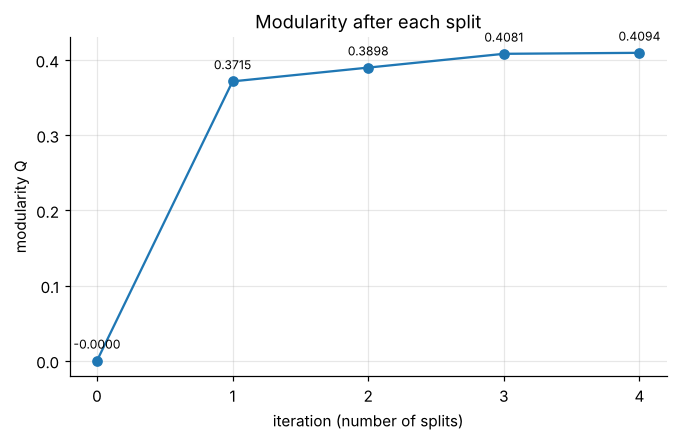

In [5]:
plt.figure(figsize=(7, 4))
qs = [float(s["Q"]) for s in snapshots]
plt.plot(range(len(qs)), qs, marker="o")
for i, q in enumerate(qs):
    plt.annotate(f"{q:.4f}", (i, q), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xticks(range(len(qs))); plt.xlabel("iteration (number of splits)"); plt.ylabel("modularity Q")
plt.title("Modularity after each split"); plt.grid(alpha=0.3); plt.show()

### Comparison of the first split with the real club fission

In [6]:
first = snapshots[1]["split"]
_, Cp, Cm = first
# decide which side is Mr. Hi's by majority vote
side_hi = Cp if sum(truth[i] == 1 for i in Cp) >= sum(truth[i] == 1 for i in Cm) else Cm
pred = np.array([1 if i in side_hi else -1 for i in nodes])
wrong = [i for i in nodes if pred[i] != truth[i]]
print(f"Nodes classified differently from the real split: {wrong}  ({len(wrong)}/{n} -> accuracy {(n-len(wrong))/n:.1%})")
for i in wrong:
    nb = list(G.neighbors(i))
    print(f"  node {i}: neighbours {nb}; real club = {G.nodes[i]['club']}")

Nodes classified differently from the real split: [8]  (1/34 -> accuracy 97.1%)
  node 8: neighbours [0, 2, 30, 32, 33]; real club = Mr. Hi


### Extension: Newman's diagonal-corrected matrix (robustness check)
The handout restricts $B$ to a block $B^{(C)}$. Newman's paper additionally subtracts the row sums on the diagonal, $B^{(C)}_{ij}\leftarrow B^{(C)}_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$, which makes the gain $\Delta Q$ of splitting $C$ *exact* (with the plain block, $s^\top B^{(C)}s/4m$ ignores the term that removes $C$'s own contribution). Below we run the same recursion with this correction for comparison. The main analysis in the rest of the notebook follows the handout (plain block).

In [7]:
snap_gen, log_gen = recursive_bisection(B, G, m, generalized=True)
print("Handout (plain block restriction):")
print("  iterations:", [(s['iteration'], round(float(s['Q']), 4)) for s in snapshots])
print("  final communities:", sorted(sorted(c) for c in snapshots[-1]['partition']))
print("Newman diagonal-corrected variant:")
print("  iterations:", [(s['iteration'], round(float(s['Q']), 4)) for s in snap_gen])
print("  final communities:", sorted(sorted(c) for c in snap_gen[-1]['partition']))

Handout (plain block restriction):
  iterations: [(0, -0.0), (1, 0.3715), (2, 0.3898), (3, 0.4081), (4, 0.4094)]
  final communities: [[0, 1, 2, 3, 7, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33], [11], [24, 25, 27, 28, 31]]
Newman diagonal-corrected variant:
  iterations: [(0, -0.0), (1, 0.3715), (2, 0.3727), (3, 0.3934)]
  final communities: [[0, 4, 5, 6, 10, 11, 16], [1, 2, 3, 7, 12, 13, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [23, 24, 25, 27, 28, 31]]


## 4. Visualisation after every split
Fixed spring layout (same positions in every picture), one colour per community, node IDs as labels. Edges between different communities are drawn dashed.

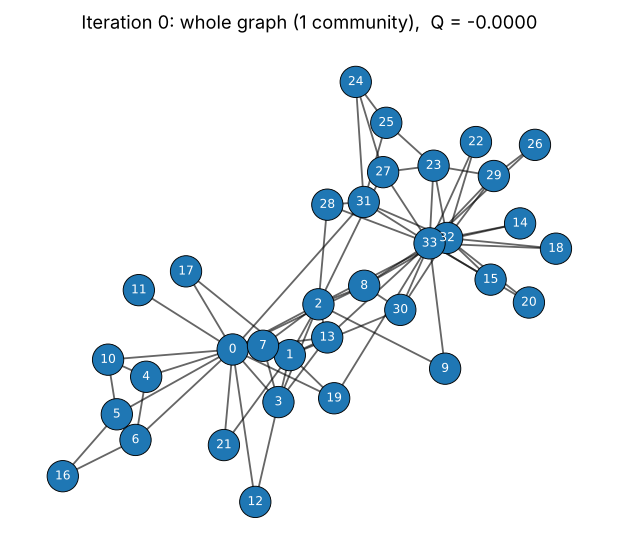

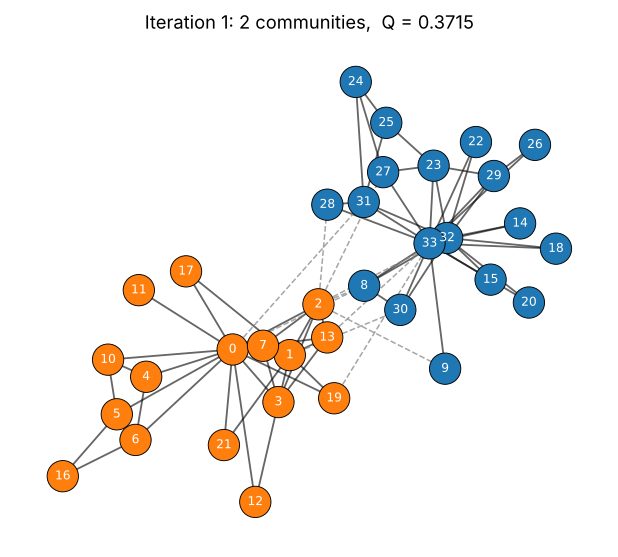

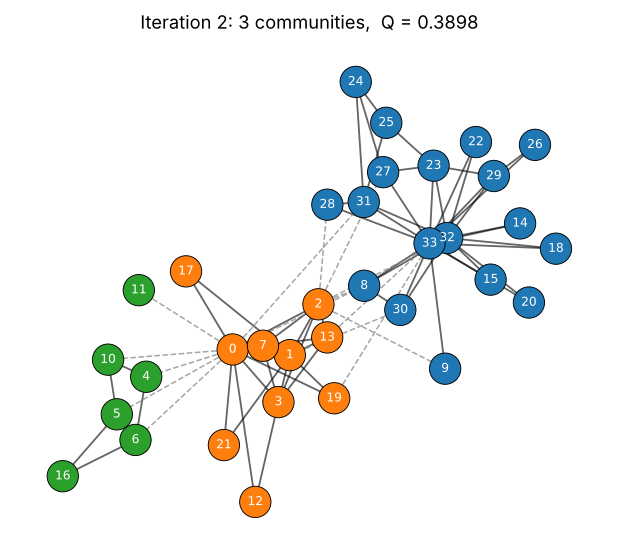

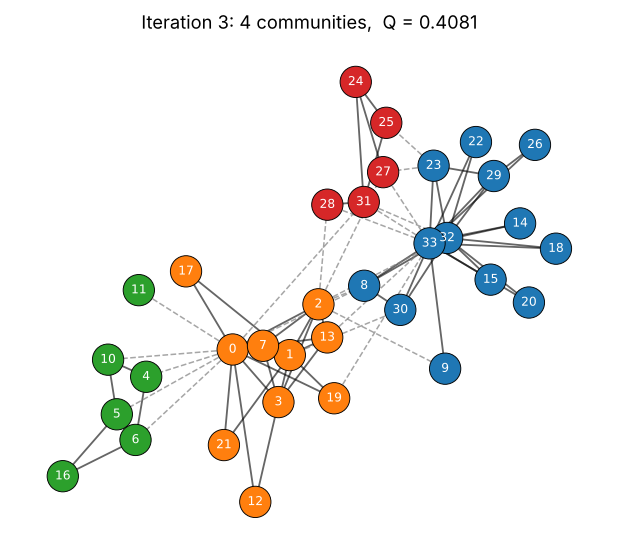

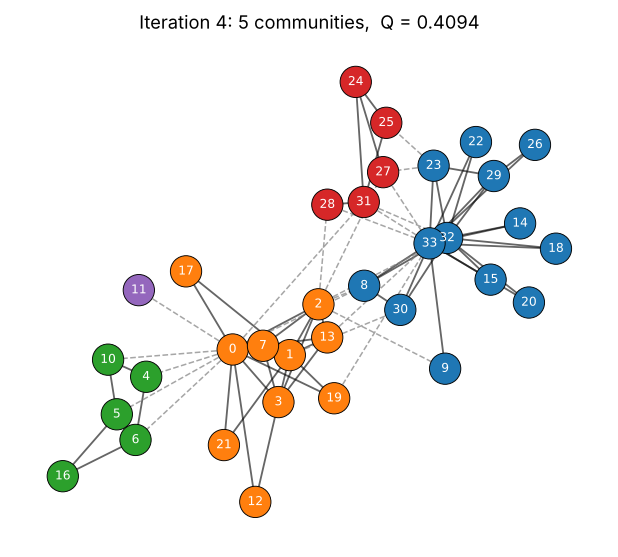

In [8]:
pos = nx.spring_layout(G, seed=7, k=0.35, iterations=200)   # fixed layout
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf"]

def draw_partition(snap, ax=None):
    part = snap["partition"]
    color_of = {}
    for ci, c in enumerate(sorted(part, key=lambda c: (-len(c), min(c)))):
        for v in c: color_of[v] = palette[ci % len(palette)]
    inside  = [(u, v) for u, v in G.edges if color_of[u] == color_of[v]]
    between = [(u, v) for u, v in G.edges if color_of[u] != color_of[v]]
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7, 6))
    nx.draw_networkx_edges(G, pos, edgelist=inside, ax=ax, width=1.2, alpha=0.6)
    nx.draw_networkx_edges(G, pos, edgelist=between, ax=ax, width=1.0, alpha=0.7, style="dashed", edge_color="gray")
    nx.draw_networkx_nodes(G, pos, node_color=[color_of[v] for v in G.nodes], node_size=420, ax=ax, edgecolors="k", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, font_size=8, font_color="white", ax=ax)
    ttl = "Iteration 0: whole graph (1 community)" if snap["iteration"] == 0 else f"Iteration {snap['iteration']}: {len(part)} communities"
    ax.set_title(f"{ttl},  Q = {snap['Q']:.4f}")
    ax.axis("off")
    if own: plt.show()

for snap in snapshots:
    draw_partition(snap)

## 5. Node metrics after each split
The handout asks for degree, betweenness and closeness centrality and the clustering coefficient "after each split". If these were computed on the *unchanged* graph $G$ they would be identical at every iteration, so there would be nothing to plot. We therefore evaluate them on the **community-induced graph** $G_t$ of iteration $t$: all 34 nodes, but only the edges *inside* a community (edges cut by a split are removed). At iteration 0 this is the original graph. The metric of a node thus tells us how important it is *within its own community* at that stage of the hierarchy.

In [9]:
def community_graph(G, partition):
    H = nx.Graph()
    H.add_nodes_from(G.nodes)
    for c in partition:
        H.add_edges_from(G.subgraph(c).edges)
    return H

METRICS = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

# metric_store[metric][iteration] -> {node: value}   (dictionary keyed by iteration, as required)
metric_store = {name: {} for name in METRICS}
for snap in snapshots:
    H = community_graph(G, snap["partition"])
    for name, fn in METRICS.items():
        metric_store[name][snap["iteration"]] = fn(H)

metric_df = {name: pd.DataFrame(d).sort_index() for name, d in metric_store.items()}   # rows = nodes, cols = iterations
for name, df in metric_df.items():
    df.columns = [f"iter {c}" for c in df.columns]

# sanity check: iteration 0 equals NetworkX on the original graph
assert np.allclose(metric_df["Betweenness centrality"]["iter 0"], pd.Series(nx.betweenness_centrality(G)))
metric_df["Degree centrality"].round(3).head(10)

,iter 0,iter 1,iter 2,iter 3,iter 4
0,0.485,0.424,0.273,0.273,0.273
1,0.273,0.242,0.242,0.242,0.242
2,0.303,0.152,0.152,0.152,0.152
3,0.182,0.182,0.182,0.182,0.182
4,0.091,0.091,0.061,0.061,0.061
5,0.121,0.121,0.091,0.091,0.091
6,0.121,0.121,0.091,0.091,0.091
7,0.121,0.121,0.121,0.121,0.121
8,0.152,0.091,0.091,0.091,0.091
9,0.061,0.030,0.030,0.030,0.030


### Full metric tables (iterations as columns)

In [10]:
for name, df in metric_df.items():
    print(f"\n=== {name} ===")
    display(df.round(3))


=== Degree centrality ===


,iter 0,iter 1,iter 2,iter 3,iter 4
0,0.485,0.424,0.273,0.273,0.273
1,0.273,0.242,0.242,0.242,0.242
2,0.303,0.152,0.152,0.152,0.152
3,0.182,0.182,0.182,0.182,0.182
4,0.091,0.091,0.061,0.061,0.061
5,0.121,0.121,0.091,0.091,0.091
6,0.121,0.121,0.091,0.091,0.091
7,0.121,0.121,0.121,0.121,0.121
8,0.152,0.091,0.091,0.091,0.091
9,0.061,0.030,0.030,0.030,0.030



=== Betweenness centrality ===


,iter 0,iter 1,iter 2,iter 3,iter 4
0,0.438,0.137,0.024,0.024,0.024
1,0.054,0.015,0.015,0.015,0.015
2,0.144,0.000,0.000,0.000,0.000
3,0.012,0.004,0.004,0.004,0.004
4,0.001,0.001,0.001,0.001,0.001
5,0.030,0.013,0.003,0.003,0.003
6,0.030,0.013,0.003,0.003,0.003
7,0.000,0.000,0.000,0.000,0.000
8,0.056,0.000,0.000,0.000,0.000
9,0.001,0.000,0.000,0.000,0.000



=== Closeness centrality ===


,iter 0,iter 1,iter 2,iter 3,iter 4
0,0.569,0.426,0.273,0.273,0.273
1,0.485,0.296,0.245,0.245,0.245
2,0.559,0.262,0.189,0.189,0.189
3,0.465,0.273,0.205,0.205,0.205
4,0.379,0.253,0.081,0.081,0.081
5,0.384,0.262,0.097,0.097,0.097
6,0.384,0.262,0.097,0.097,0.097
7,0.440,0.253,0.175,0.175,0.175
8,0.516,0.265,0.265,0.208,0.208
9,0.434,0.250,0.250,0.190,0.190



=== Clustering coefficient ===


,iter 0,iter 1,iter 2,iter 3,iter 4
0,0.150,0.187,0.361,0.361,0.361
1,0.333,0.429,0.429,0.429,0.429
2,0.244,0.900,0.900,0.900,0.900
3,0.667,0.667,0.667,0.667,0.667
4,0.667,0.667,0.000,0.000,0.000
5,0.500,0.500,0.333,0.333,0.333
6,0.500,0.500,0.333,0.333,0.333
7,1.000,1.000,1.000,1.000,1.000
8,0.500,1.000,1.000,1.000,1.000
9,0.000,0.000,0.000,0.000,0.000


## 6. Evolution of each metric across iterations
Left: every node as a thin grey line, with the five highest-ranked nodes (by mean value over all iterations) highlighted and labelled. Right: heat-map of all 34 nodes.

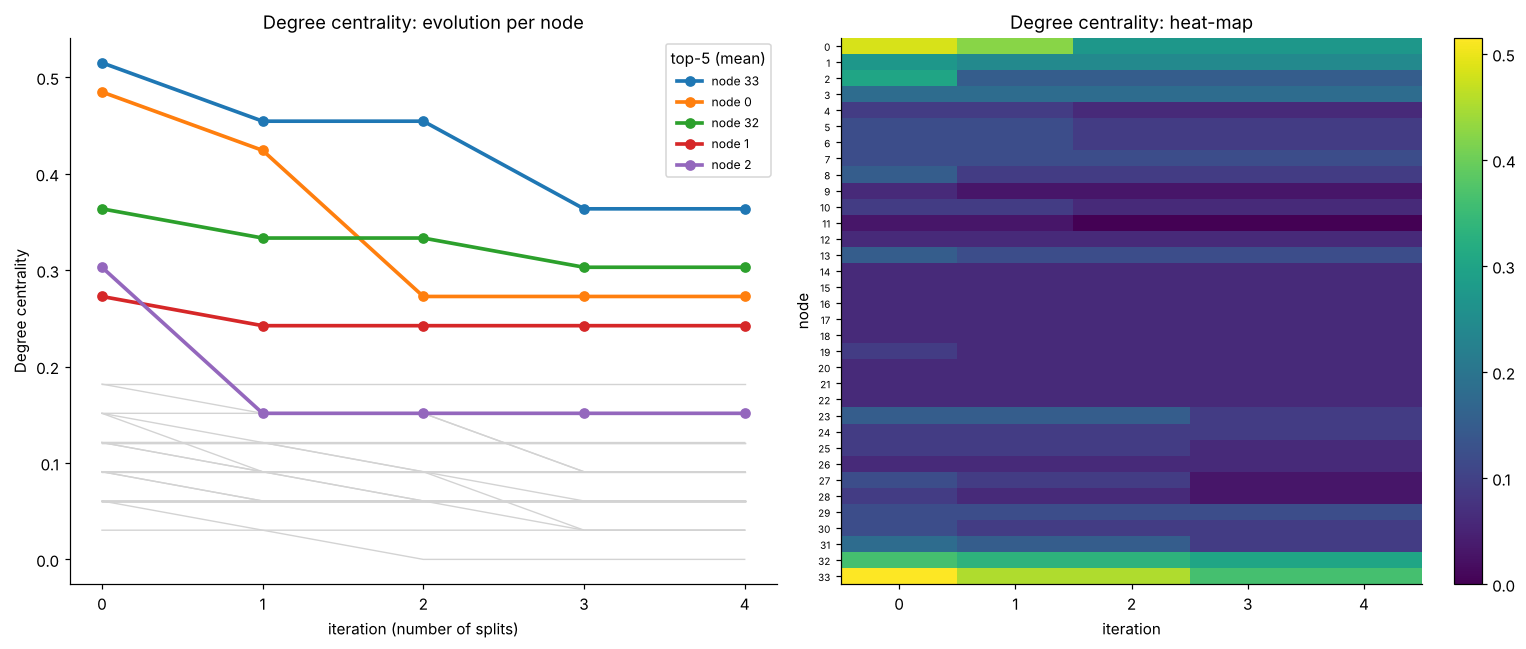

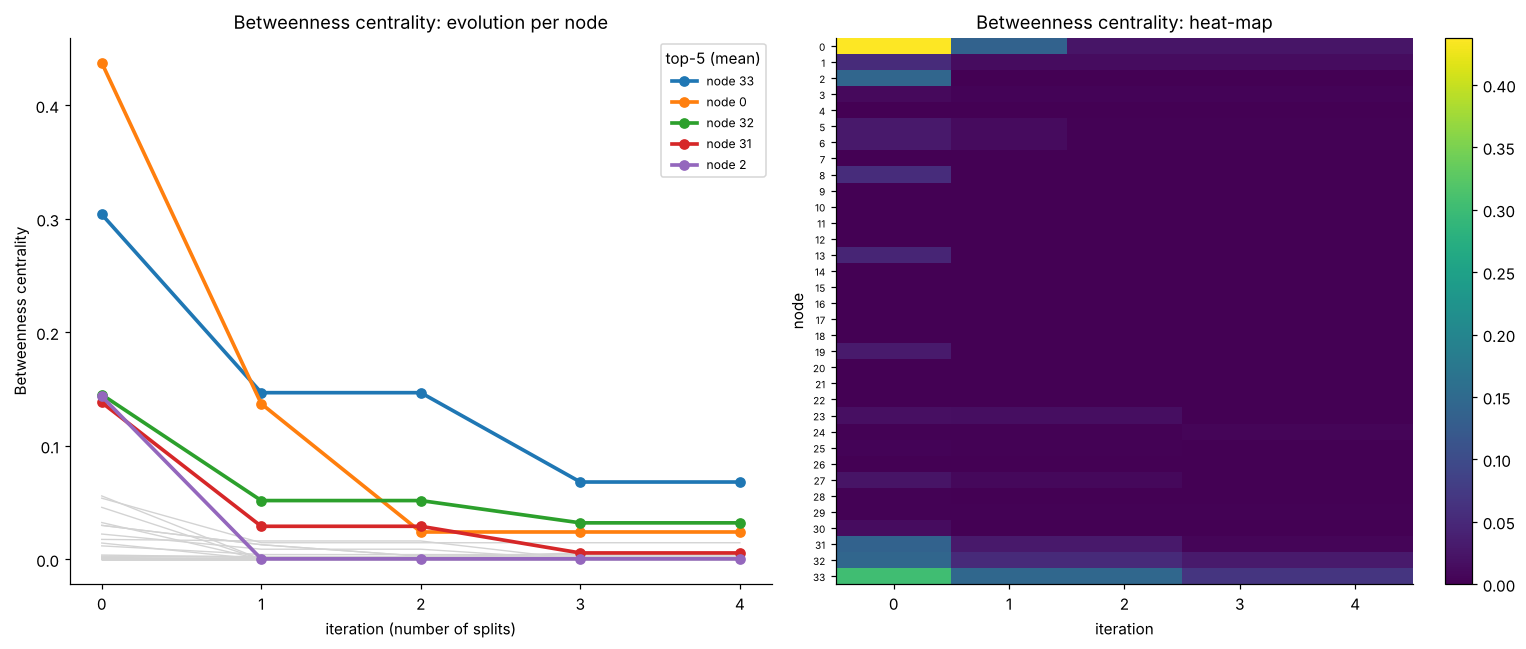

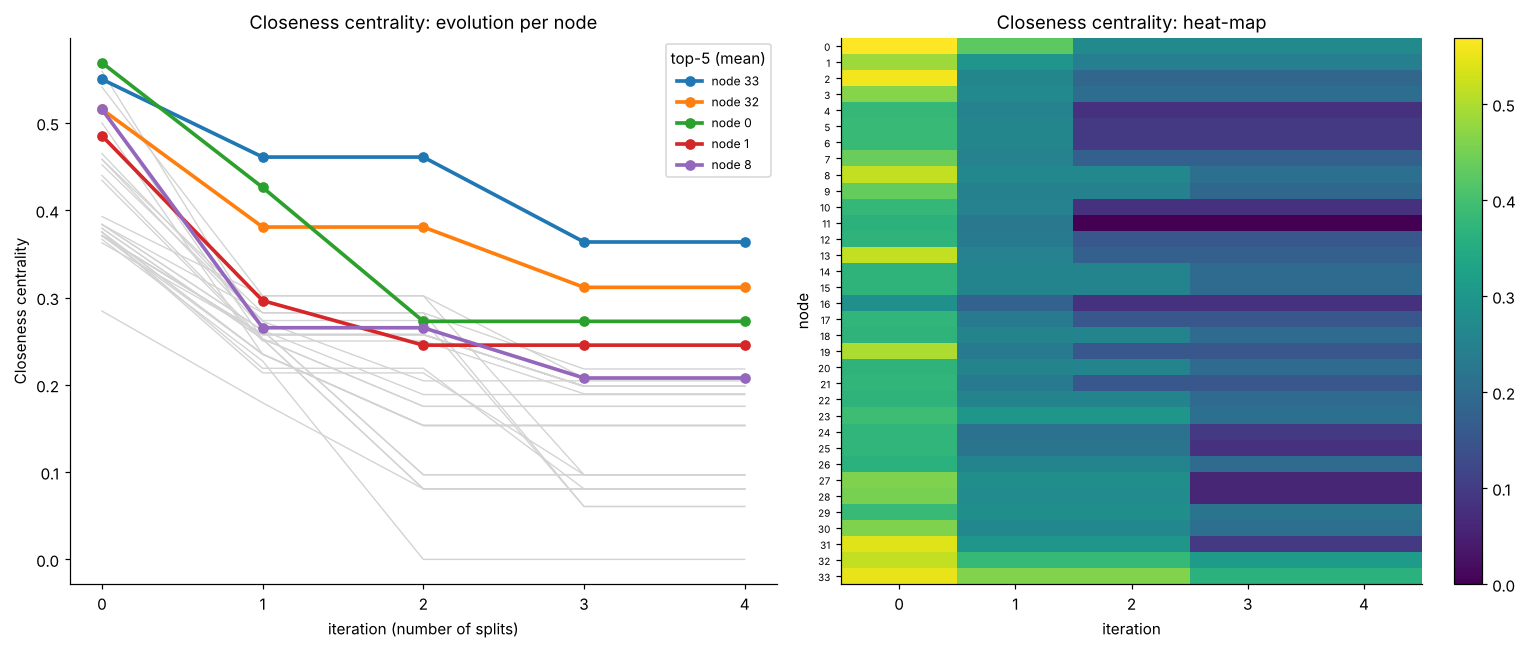

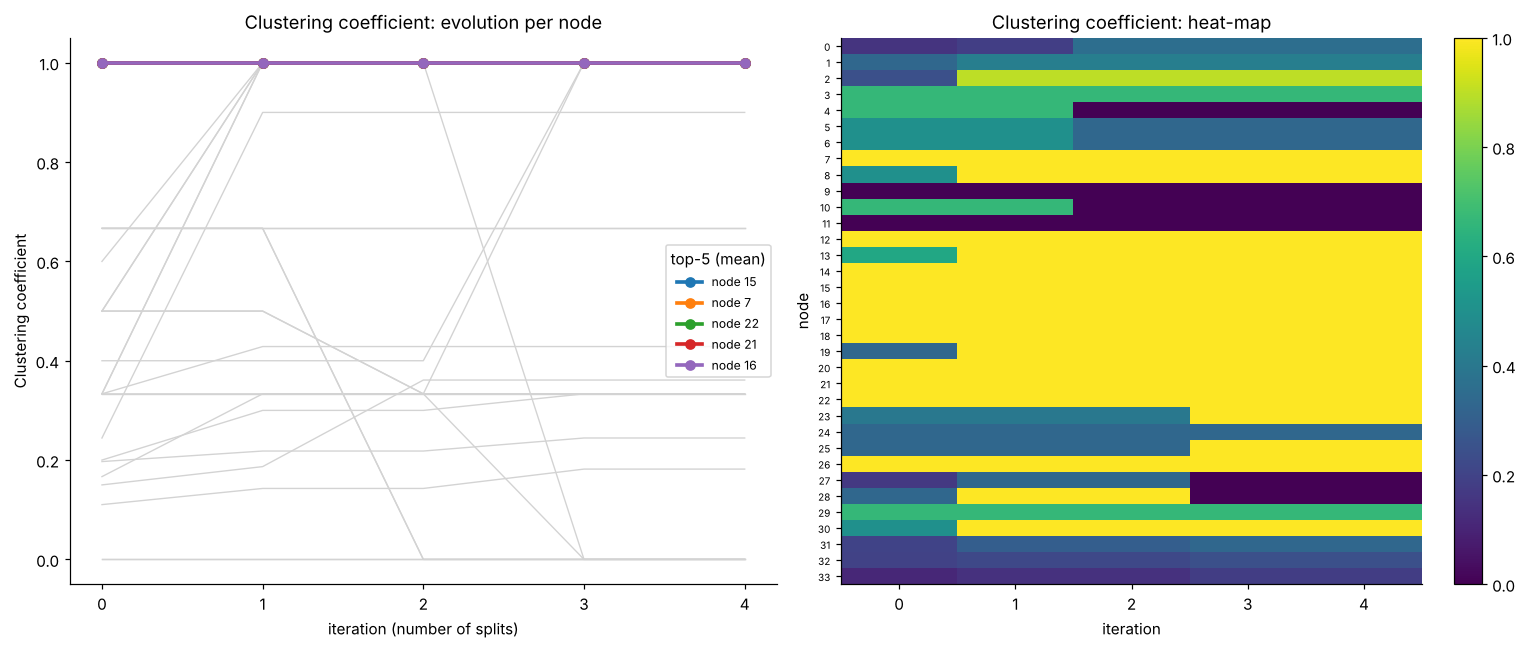

In [11]:
iters = sorted(snapshots[i]["iteration"] for i in range(len(snapshots)))
top5_store = {}
for name, df in metric_df.items():
    top5 = df.mean(axis=1).sort_values(ascending=False).head(5).index.tolist()
    top5_store[name] = top5
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.1, 1]})
    for v in df.index:
        ax1.plot(iters, df.loc[v].values, color="lightgray", lw=0.9, zorder=1)
    for j, v in enumerate(top5):
        ax1.plot(iters, df.loc[v].values, color=palette[j], lw=2.4, marker="o", label=f"node {v}", zorder=3)
    ax1.set_xticks(iters); ax1.set_xlabel("iteration (number of splits)"); ax1.set_ylabel(name)
    ax1.set_title(f"{name}: evolution per node"); ax1.legend(title="top-5 (mean)", fontsize=8, loc="best")
    im = ax2.imshow(df.values, aspect="auto", cmap="viridis")
    ax2.set_xticks(range(len(iters))); ax2.set_xticklabels(iters)
    ax2.set_yticks(range(n)); ax2.set_yticklabels(df.index, fontsize=6.5)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node"); ax2.set_title(f"{name}: heat-map")
    plt.colorbar(im, ax=ax2, fraction=0.046)
    plt.tight_layout(); plt.show()

### Bar-plot view: metrics for every node, iteration 0 vs. final partition

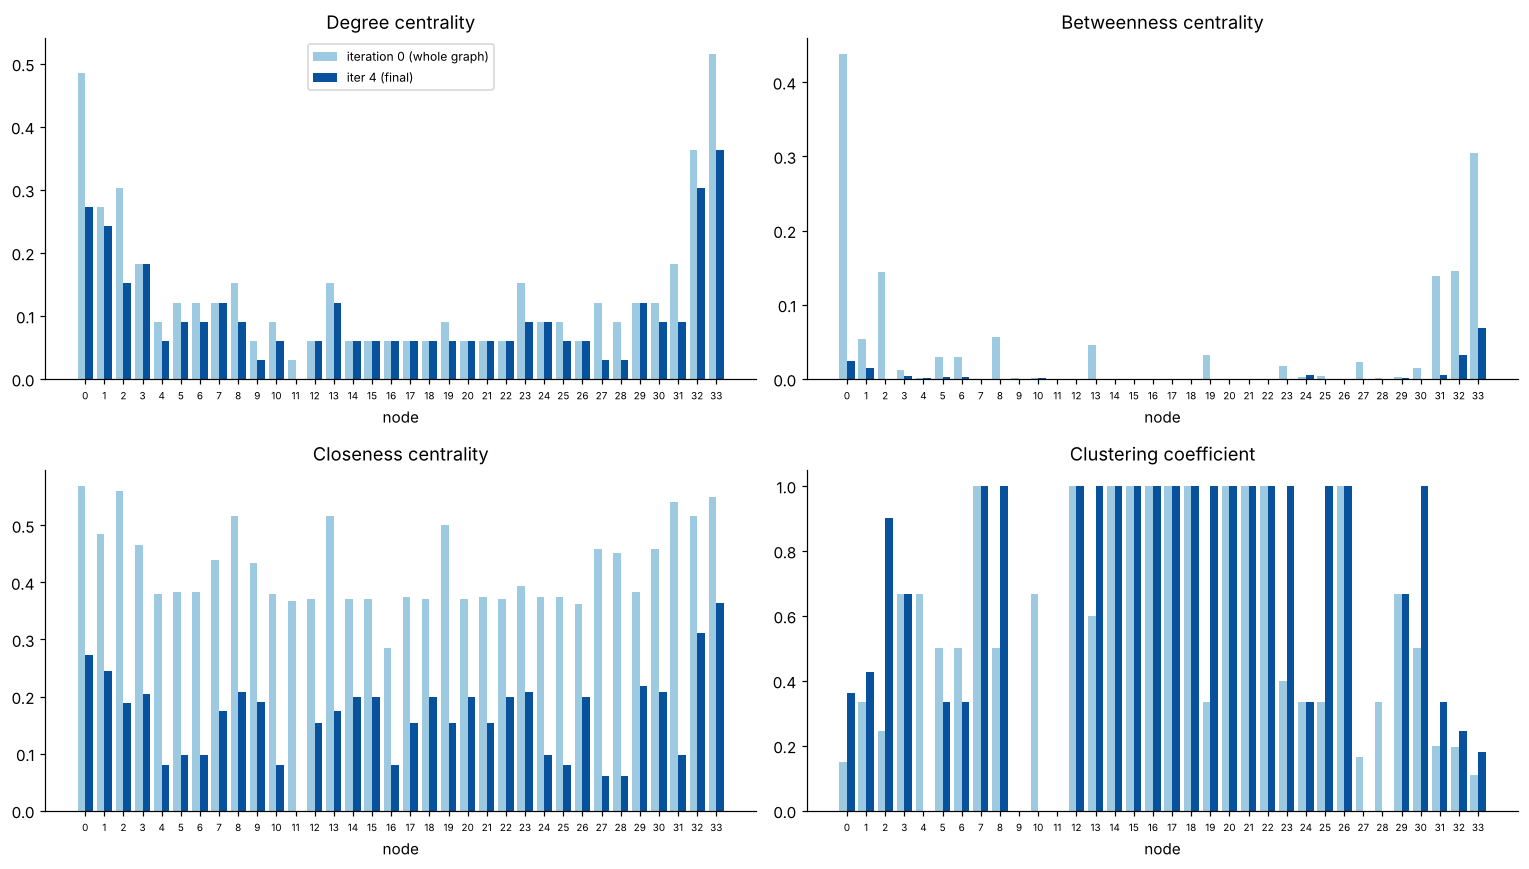

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
last = f"iter {snapshots[-1]['iteration']}"
for ax, (name, df) in zip(axes.ravel(), metric_df.items()):
    x = np.arange(n); w = 0.4
    ax.bar(x - w/2, df["iter 0"], w, label="iteration 0 (whole graph)", color="#9ecae1")
    ax.bar(x + w/2, df[last], w, label=f"{last} (final)", color="#08519c")
    ax.set_xticks(x); ax.set_xticklabels(df.index, fontsize=6.5); ax.set_title(name); ax.set_xlabel("node")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Quantities used in the discussion

In [13]:
# Mean rank of each node across iterations (1 = most central), per metric
rank_tables = {name: df.rank(ascending=False, method="min") for name, df in metric_df.items()}
combined = pd.DataFrame({name: rt.mean(axis=1) for name, rt in rank_tables.items()})
combined["overall mean rank"] = combined.mean(axis=1)
combined = combined.sort_values("overall mean rank")
print("Nodes with the best (lowest) average rank across all metrics and iterations:")
display(combined.head(8).round(2))

print("\nHow many iterations is each node in the top-3 of each metric?")
top3_counts = pd.DataFrame({name: (rt <= 3).sum(axis=1) for name, rt in rank_tables.items()})
display(top3_counts[top3_counts.sum(axis=1) > 0].sort_values(list(top3_counts.columns), ascending=False))

# Drop in each metric from iteration 0 to the final iteration (average over nodes)
change = pd.DataFrame({name: df[last] - df["iter 0"] for name, df in metric_df.items()})
print("\nMean change (final - iteration 0) over all nodes:")
display(change.mean().round(4).to_frame("mean change"))

# Nodes whose betweenness / closeness fall most -> they were bridges between the cut communities
print("Largest betweenness drops (final - iter 0):")
display(change["Betweenness centrality"].sort_values().head(5).round(3).to_frame())
print("Largest closeness drops:")
display(change["Closeness centrality"].sort_values().head(5).round(3).to_frame())

# community sizes + intra/inter edges at the end
final_part = snapshots[-1]["partition"]
lab = {v: i for i, c in enumerate(final_part) for v in c}
inter = sum(lab[u] != lab[v] for u, v in G.edges)
print(f"\nFinal partition: {len(final_part)} communities, {m-inter} intra-community edges, {inter} edges cut ({inter/m:.1%}).")

Nodes with the best (lowest) average rank across all metrics and iterations:


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient,overall mean rank
33,1.0,1.2,1.4,30.0,8.40
0,2.6,2.6,3.4,25.6,8.55
32,2.4,2.4,2.8,28.4,9.00
8,10.8,13.6,7.4,4.2,9.00
23,8.0,10.2,7.0,13.8,9.75
1,4.2,5.4,8.2,21.6,9.85
30,11.4,15.2,8.6,4.2,9.85
13,8.0,14.0,17.2,4.0,10.80



How many iterations is each node in the top-3 of each metric?


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
33,5,5,5,0
32,5,5,4,0
0,5,4,4,0
31,0,1,1,0
23,0,0,1,2
2,0,0,1,0
7,0,0,0,5
12,0,0,0,5
14,0,0,0,5
15,0,0,0,5



Mean change (final - iteration 0) over all nodes:


,mean change
Degree centrality,-0.0374
Betweenness centrality,-0.0392
Closeness centrality,-0.2616
Clustering coefficient,0.0700


Largest betweenness drops (final - iter 0):


,Betweenness centrality
0,-0.413
33,-0.236
2,-0.143
31,-0.133
32,-0.113


Largest closeness drops:


,Closeness centrality
31,-0.444
27,-0.398
28,-0.391
2,-0.371
11,-0.367



Final partition: 5 communities, 57 intra-community edges, 21 edges cut (26.9%).


## 8. Discussion

### 8.1 What the algorithm found
* **Number of communities.** The recursion accepted 4 splits and ended with 5 communities of sizes 13, 10, 5, 5 and 1. Modularity rose from $0$ (everyone together) to $0.3715$, $0.3898$, $0.4081$ and finally $0.4094$. Every accepted split gave a positive gain ($0.3715$, $0.0183$, $0.0183$, $0.0013$), but this is an observation for this run and not something the eigenvalue test guarantees.
* **First split.** The leading eigenvector of $B$ ($\lambda_1 = 4.977$) divides the club into groups of 16 and 18 with $Q = 0.3715$, the value Newman (2006) reports. Compared with Zachary's recorded fission, **33 of 34 members** are on the correct side. Only node 8 is not: it has two neighbours on Mr. Hi's side (0, 2) and three on the president's side (30, 32, 33), so the friendship structure alone pulls it across. The algorithm never saw the historical labels, yet it recovers almost exactly the split that really happened.
* **Why the recursion stopped.** The blocks of size 10, 5, 5 and 13 still have a positive leading eigenvalue (about 2.57, 2.15, 1.88 and 2.36). They were not split because the sign rule put all of their nodes on the same side, so no two-way split exists with this rule. The singleton {11} stops because $\lambda_1 = -0.006 \le 0$. The recursion therefore ended through the one-sided-eigenvector rule and mostly not through the $\lambda_1\le 0$ test. This happens because the plain block $B^{(C)}$ is used exactly as the handout defines it, with no diagonal correction.
* **The last split is almost cosmetic.** It separates node 11, whose only friend is node 0, and raises $Q$ by only $0.0013$. The more meaningful picture is the four-group partition of iteration 3. In the final partition 57 of the 78 edges (73%) lie inside communities and 21 are cut.

### 8.2 The four metrics and their evolution
*Metrics are computed on the community-induced graph (all 34 nodes, only edges inside communities, see §5). Degree and betweenness are normalised by the whole network, and closeness is scaled by the size of the node's component, so a value mostly says "how important is this node inside its own community, relative to the whole club". Iteration 0 equals the usual whole-graph values.*

**8.2.1 Degree centrality.** Degree centrality is the fraction of the other nodes a node is directly connected to. On the whole graph the top five are 33 (0.515), 0 (0.485), 32 (0.364), 2 (0.303) and 1 (0.273); after the last split they are 33 (0.364), 32 (0.303), 0 (0.273), 1 (0.242) and 3 (0.182). Nodes 33, 32, 0 and 1 are in the top five at all five stages. Degree can only fall, and only when a split cuts an edge, so each split removes edges *between* communities and leaves communities with fewer inter-connections and more intra-connections. The hubs lose some edges too (node 0: 0.485 → 0.273, node 33: 0.515 → 0.364), but they stay on top because most of their neighbours are in their own community. In the final communities node 0 is adjacent to all 9 other members of its group and node 33 to all 12 of its own.

**8.2.2 Betweenness centrality.** Betweenness counts how many shortest paths pass through a node, so it identifies the "communicators" that control information flow. On the whole graph the leaders are 0 (0.438), 33 (0.304), 32 (0.145), 2 (0.144) and 31 (0.138); at the end they are 33 (0.068), 32 (0.032), 0 (0.024) and 1 (0.015). Nodes 0, 33 and 32 are in the top five at all stages. Betweenness collapses for almost everyone because the edges that were cut carried most of the shortest paths between the two factions. The biggest losses are node 0 (0.438 → 0.137 → 0.024), node 33 (0.304 → 0.068), node 2 (0.144 → 0.000) and node 31 (0.138 → 0.006). These were bridges to groups that are now separate. Node 31 is a strong broker only until iteration 2 and loses that role once the group around it is divided.

**8.2.3 Closeness centrality.** Closeness measures how quickly a node reaches the others. On the whole graph the values are close together (0 at 0.569, 2 at 0.559, 33 at 0.550, 31 at 0.541, and 8, 13 and 32 tied at 0.516), because the graph is small and compact. After the last split the top is 33 (0.364), 32 (0.312), 0 (0.273) and 1 (0.245). These "natural leaders" are the ones that stay at or near the top of their communities. Closeness *falls* for almost every node (mean change $-0.26$; node 0: 0.569 → 0.273), since after a cut a node can only reach its own community and the measure is scaled by that component's size. Node 11 drops to 0 because it ends up isolated. So the ranking is stable even though the raw values fall.

**8.2.4 Clustering coefficient.** The clustering coefficient is the fraction of a node's neighbours that are also connected to each other. It tends to rise after splits (mean 0.571 → 0.684 after the first split, then about 0.64). Cutting inter-community edges removes neighbours that did not know the rest of a node's neighbourhood. For example node 2 rises from 0.244 to 0.900, node 19 from 0.333 to 1.0, node 8 from 0.5 to 1.0 and node 13 from 0.6 to 1.0. At the end 17 nodes (7, 8, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 30) have exactly 1.0, meaning all their neighbours are mutual friends. Many of these have only two or three neighbours, which makes 1.0 easy to reach. Other nodes drop to 0 when a split leaves them with neighbours that do not know each other (4, 10, 27, 28 and the isolated node 11; node 9 is 0 from the start). The hubs keep low clustering: node 33 goes 0.110 → 0.182, node 32 0.197 → 0.244 and node 0 0.150 → 0.361, because their neighbours belong to different groups. By community, the mean clustering is 0.836 for {0,1,2,3,7,12,13,17,19,21}, 0.776 for the 13-node community, 0.333 for both {4,5,6,10,16} and {24,25,27,28,31}, and 0 for {11}. So the two big communities are the most tightly knit.

### 8.3 Which nodes stay central across splits?
* **The two faction leaders and node 32.** Nodes 0 (Mr. Hi) and 33 (the president) are in the top five for degree and betweenness at every stage, and node 32 does the same. For closeness, node 33 is in the top five at every stage and node 0 at every stage except iteration 2. Splitting the graph does not dethrone them: they remain the hubs of their own groups, which fits the leading roles they played in the real split.
* **A lieutenant.** Node 1 is in the top five for degree at all stages and for closeness and betweenness at the last two, so it is the main secondary figure on Mr. Hi's side.
* **Different centralities, different roles.** Centrality and clustering identify different nodes. The hubs (33, 32, 0) have high degree, betweenness and closeness but *low* clustering because they connect groups. The nodes with the highest clustering (7, 8, 12, 13, 14, …) have few, tightly connected neighbours and sit inside cliques. This is the difference between a broker and a member of a tight group.

### 8.4 How community structure shapes the metrics
1. **Values fall, rankings hold.** Cutting inter-community edges lowers degree, betweenness and closeness for most nodes (mean changes $-0.037$, $-0.039$ and $-0.262$), while the nodes at the top mostly stay there.
2. **Hubs become local hubs.** In a small community the hub is adjacent to everyone, so its degree and closeness are determined by the community's size.
3. **Bridges lose their role.** The heavily used paths in the full graph are the edges between factions. Once those are cut, betweenness inside a community only reflects how a node joins sub-groups of that community.
4. **Clustering rises.** Removing sparse cross-community edges leaves denser groups, and the mean clustering goes up by 0.07.

### 8.5 Comparison with the historical split
The first split (16 versus 18 nodes) agrees with the historical factions for 33 of 34 members: the 16-node group is entirely "Mr. Hi", and the 18-node group has 17 "Officer" members plus node 8. The five final communities refine this division. Communities {0,1,2,3,7,12,13,17,19,21}, {4,5,6,10,16} and {11} contain only "Mr. Hi" members, {24,25,27,28,31} contains only "Officer" members, and the 13-node community has 12 "Officer" members plus node 8. The later splits therefore find sub-groups *inside* the two factions.

### 8.6 Limitations
* **Plain block restriction.** The handout's $B^{(C)}$ ignores a diagonal term that makes $\Delta Q$ exact. As a robustness check (§3), Newman's corrected matrix with a $\Delta Q>0$ test gives the same first split but differs from iteration 2 on, and ends with 4 communities and $Q = 0.3934$, without the singleton. The later splits are therefore the least robust part of the result.
* **Heuristic.** Spectral bisection with sign rounding approximates modularity maximisation, which is NP-hard. It does not guarantee the best discrete split. Later splits add only a little ($0.3715 \to 0.4094$), so the first split is by far the most important one.
* **Definition-dependent metrics.** The metric values depend on computing them on the community-induced graph and on the order of splitting. Another definition (for example computing metrics inside each community separately) would give different values, but the same leaders.

## 9. Conclusion
Modularity measures how much more strongly a group of nodes is connected inside than a random graph with the same degrees would predict. The modularity matrix $B = A - \frac{kk^\top}{2m}$ is the actual adjacency matrix minus the expected edge counts of the degree-preserving null model. It is real and symmetric, each row sums to zero, and the modularity of a two-way split is $Q = \frac{1}{4m}s^\top B s$.

Spectral partitioning relaxes $s$ to a unit real vector. By the Rayleigh–Ritz theorem the maximum of $s^\top B s$ is the largest eigenvalue $\lambda_1$, attained by the leading eigenvector, whose signs give the two groups. This is an approximation and not a guarantee of the best discrete split. Recursive bisection applies the same procedure to the restricted matrix of each community. A community with $\lambda_1^{(C)}\le 0$ cannot be improved by any split (Theorem 3), so it is left alone. A positive eigenvalue only allows a split, and in our run four blocks with positive $\lambda_1$ were not split because their leading eigenvector had a single sign.

On the Karate Club graph the method produced 5 communities with $Q = 0.4094$. The first split reproduces the historical division for 33 of 34 members, with node 8 the only exception, and the later splits find sub-groups inside the two factions.

For the node metrics, nodes 0 and 33, together with node 32, are the most central by degree and betweenness at every stage, and node 33 also by closeness, while node 1 is the main lieutenant of Mr. Hi's side. These hubs keep low clustering because they connect different groups, whereas the nodes with the highest clustering sit inside tight cliques with few neighbours. As the club is divided, degree, betweenness and closeness fall for most nodes and clustering rises, which shows that cutting along community boundaries removes the bridges and leaves dense, tightly knit groups with a local hub at the centre of each.

## References
1. M. E. J. Newman, *Modularity and community structure in networks*, Proc. Natl. Acad. Sci. USA **103**(23), 8577–8582 (2006).
2. W. W. Zachary, *An information flow model for conflict and fission in small groups*, Journal of Anthropological Research **33**(4), 452–473 (1977).
3. A. A. Hagberg, D. A. Schult, P. J. Swart, *Exploring network structure, dynamics, and function using NetworkX*, SciPy 2008.